## 1. Environment & Repository Setup

In [1]:
# Cell 1: Clone or update repo & install requirements
import os

repo_dir = "/kaggle/working/YOLO_object-segmentation"
if not os.path.exists(repo_dir):
    !git clone https://github.com/XiaoSha59/YOLO_object-segmentation.git
    %cd {repo_dir}
else:
    %cd {repo_dir}
    !git pull

!pip install -r requirements.txt

Cloning into 'YOLO_object-segmentation'...
remote: Enumerating objects: 65, done.
remote: Counting objects: 100% (65/65), done.
remote: Compressing objects: 100% (43/43), done.
remote: Total 65 (delta 22), reused 58 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (65/65), 20.21 MiB | 10.27 MiB/s, done.
Resolving deltas: 100% (22/22), done.
/kaggle/working/YOLO_object-segmentation
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


## 2. Dataset Preparation & Mask Verification

DOWNLOAD & PREPARE PACKAGE-SEG 400 DATASET
[1/3] Downloading Package-Seg dataset from https://github.com/ultralytics/assets/releases/download/v0.0.0/package-seg.zip...
Downloading: 100.0% (103.1MB / 103.1MB)
[+] Download completed.
[+] SHA-256 checksum verified.
[2/3] Extracting archive to /kaggle/working/YOLO_object-segmentation/datasets/package-seg...
Traceback (most recent call last):
  File "/usr/lib/python3.13/shutil.py", line 860, in move
    os.rename(src, real_dst)
    ~~~~~~~~~^^^^^^^^^^^^^^^
OSError: [Errno 22] Invalid argument: '/kaggle/working/YOLO_object-segmentation/datasets/package-seg' -> '/kaggle/working/YOLO_object-segmentation/datasets/package-seg/package-seg'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/kaggle/working/YOLO_object-segmentation/scripts/download_data.py", line 173, in <module>
    main()
    ~~~~^^
  File "/kaggle/working/YOLO_object-segmentation/scripts/download_data.py", line 167, i

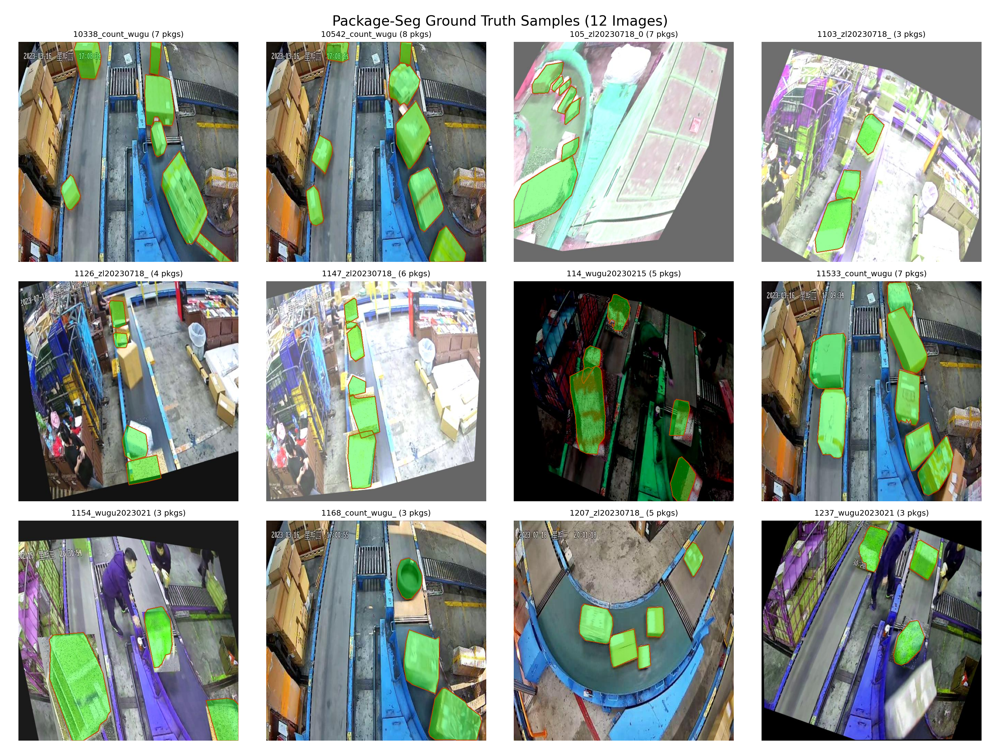

In [2]:
# Cell 2: Download Package-Seg archive, filter duplicate .rf. augmentations, lock 400 subset, verify masks
!python scripts/download_data.py
!python scripts/check_dataset.py

# Display 12-sample visual preview inline
from IPython.display import Image, display
if os.path.exists("figures/dataset_samples.png"):
    display(Image("figures/dataset_samples.png", width=900))

## 3. Smoke Test (VRAM & Segmentation Pipeline Check)

In [3]:
# Cell 3: 1-epoch smoke test with YOLO26m-seg to verify VRAM headroom
!python scripts/train.py --smoke-test

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

 RUNNING SMOKE TEST: YOLO26m-seg (1 epoch)
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/YOLO_object-segmentation/datasets/package-seg/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, er

## 4. Sequential Model Training with Checkpoint Protection

In [4]:
# Cell 4A: Train YOLO26n-seg (~20-30 mins)
!python scripts/train.py --model yolo26n

# Download backup.zip (contains best.pt, last.pt, results.csv, results.png)
from IPython.display import FileLink
FileLink("backup.zip")


 TARGET MODELS: ['yolo26n-seg']
 CONFIG: epochs=30, batch=4, imgsz=512, optimizer=AdamW

 Training model: yolo26n-seg...
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/YOLO_object-segmentation/datasets/package-seg/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max

/kaggle/working/YOLO_object-segmentation/backup.zip

In [5]:
# Cell 4B: Train YOLO26s-seg (~1 - 1.5 hours)
!python scripts/train.py --model yolo26s

# Download updated backup.zip
from IPython.display import FileLink
FileLink("backup.zip")


 TARGET MODELS: ['yolo26s-seg']
 CONFIG: epochs=30, batch=4, imgsz=512, optimizer=AdamW

 Training model: yolo26s-seg...
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/YOLO_object-segmentation/datasets/package-seg/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max

/kaggle/working/YOLO_object-segmentation/backup.zip

In [6]:
# Cell 4C: Train YOLO26m-seg (~2 - 3 hours)
!python scripts/train.py --model yolo26m

# Download final backup.zip
from IPython.display import FileLink
FileLink("backup.zip")


 TARGET MODELS: ['yolo26m-seg']
 CONFIG: epochs=30, batch=4, imgsz=512, optimizer=AdamW

 Training model: yolo26m-seg...
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/YOLO_object-segmentation/datasets/package-seg/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max

/kaggle/working/YOLO_object-segmentation/backup.zip

## 5. Benchmark Evaluation on Test Split

In [7]:
# Cell 5: Benchmark evaluation on test set (conf=0.001)
!python scripts/eval_test.py

# Display benchmark results table
import pandas as pd
if os.path.exists("metrics/comparison_test.csv"):
    df = pd.read_csv("metrics/comparison_test.csv")
    display(df)

 BENCHMARK EVALUATION ON TEST SET (Package-Seg, conf=0.001)
 Checkpoint not found for yolo26n-seg. Skipping.
 Checkpoint not found for yolo26s-seg. Skipping.
 Checkpoint not found for yolo26m-seg. Skipping.
 No model checkpoints found for evaluation.


## 6. Package Counting Demo

In [8]:
# Cell 6: Automated package counting using instance segmentation masks (conf=0.25)
!python scripts/demo_count.py

# Display annotated counting output image inline
if os.path.exists("figures/demo_counting.png"):
    display(Image("figures/demo_counting.png", width=700))

 Checkpoint best.pt not found! Train models first or specify --model.


## 7. Cloud Backup to Kaggle Dataset (Optional)

In [9]:
# Cell 7: Upload trained weights and figures to your private Kaggle Dataset
!python scripts/upload_kaggle.py

[+] Created backup/dataset-metadata.json
[*] Uploading checkpoints from backup to Kaggle Dataset (salala1706/yolo26-package-seg-checkpoints)...
[+] Successfully created new Kaggle dataset!
Skipping folder: yolo26m-seg; use '--dir-mode' to upload folders
Skipping folder: yolo26s-seg; use '--dir-mode' to upload folders
Skipping folder: yolo26n-seg; use '--dir-mode' to upload folders
Dataset creation error: Please upload at least one file

